# CE1110: Tarea 1 — Apartado 2.2

**Generación y caracterización de tres casos de señal contaminada.** Se usan datos sintéticos, semillas distintas y un script reproducible que crea WAV/NPY, gráficos, metadatos y una tabla de SNR.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image

BASE = Path.cwd().resolve()
if not (BASE / "src" / "generacion_senales.py").exists():
    BASE = BASE / "proyecto_grupal_1_reduccion_ruido" / "tarea1"
if not (BASE / "src" / "generacion_senales.py").exists():
    raise FileNotFoundError("Abrir el notebook desde carpeta tarea1 o raíz del repositorio.")
sys.path.insert(0, str(BASE / "src"))
import generacion_senales as g
print("Carpeta de trabajo:", BASE)

Carpeta de trabajo: /mnt/data/ASM_Tarea1_Integrada/tarea1


## 1. Generar desde cero

Se genera una referencia multitono común; tres realizaciones de ruido independientes y escaladas a la potencia necesaria para las SNR indicadas. La ganancia global contra recorte se aplica uniformemente a todos los casos.

In [2]:
registros = g.generar(BASE)
config = json.loads((BASE / "metadatos" / "configuraciones.json").read_text(encoding="utf-8"))
print("fs =", config["fs_hz"], "Hz; N_bloque =", config["n_bloque"], "; L =",config["n_total"])
print("Duración total =",config["duracion_s"],"s; ganancia anticlip =",config["ganancia_global_anticlip"])

Caso 1: objetivo=5.000 dB, medida=5.000000000000 dB, pico=0.4517


Caso 2: objetivo=3.000 dB, medida=3.000000000000 dB, pico=0.7709


Caso 3: objetivo=0.000 dB, medida=0.000000000000 dB, pico=0.9500
fs = 8192 Hz; N_bloque = 1024 ; L = 16384
Duración total = 2.0 s; ganancia anticlip = 0.521849406577605


## 2. Validar matemáticamente SNR, energía y señales

In [3]:
datos = pd.read_csv(BASE / "resultados" / "metricas_generacion.csv")
display(datos[["caso","semilla","fs_hz","n_bloque","n_total","snr_objetivo_db","snr_obtenida_db","error_snr_db","pico_contaminada"]])
assert (np.abs(datos["error_snr_db"]) < 1e-10).all()
for k in (1,2,3):
    p = BASE / "pruebas" / f"caso_{k}"
    s, r, x = [np.load(p / f"{nom}.npy") for nom in ("limpia", "ruido", "contaminada")]
    assert np.allclose(x, s+r, rtol=0, atol=1e-12)
    assert abs(g.energia_por_bandas(x).sum() - 100) < 1e-10
print("Validación de los tres casos superada.")

,caso,semilla,fs_hz,n_bloque,n_total,snr_objetivo_db,snr_obtenida_db,error_snr_db,pico_contaminada
0,1,20261021,8192,1024,16384,5.0,5.0,-8.881784e-16,0.451668
1,2,20261022,8192,1024,16384,3.0,3.0,8.881784e-16,0.770892
2,3,20261023,8192,1024,16384,0.0,0.0,0.000000e+00,0.950000


Validación de los tres casos superada.


## 3. Cuatro representaciones por caso

Tiempo, magnitud FFT, fase de componentes significativas y porcentaje de energía por bandas. La figura de PSD estimada por Welch complementa la caracterización del ruido.

CASO 1: RESUMEN


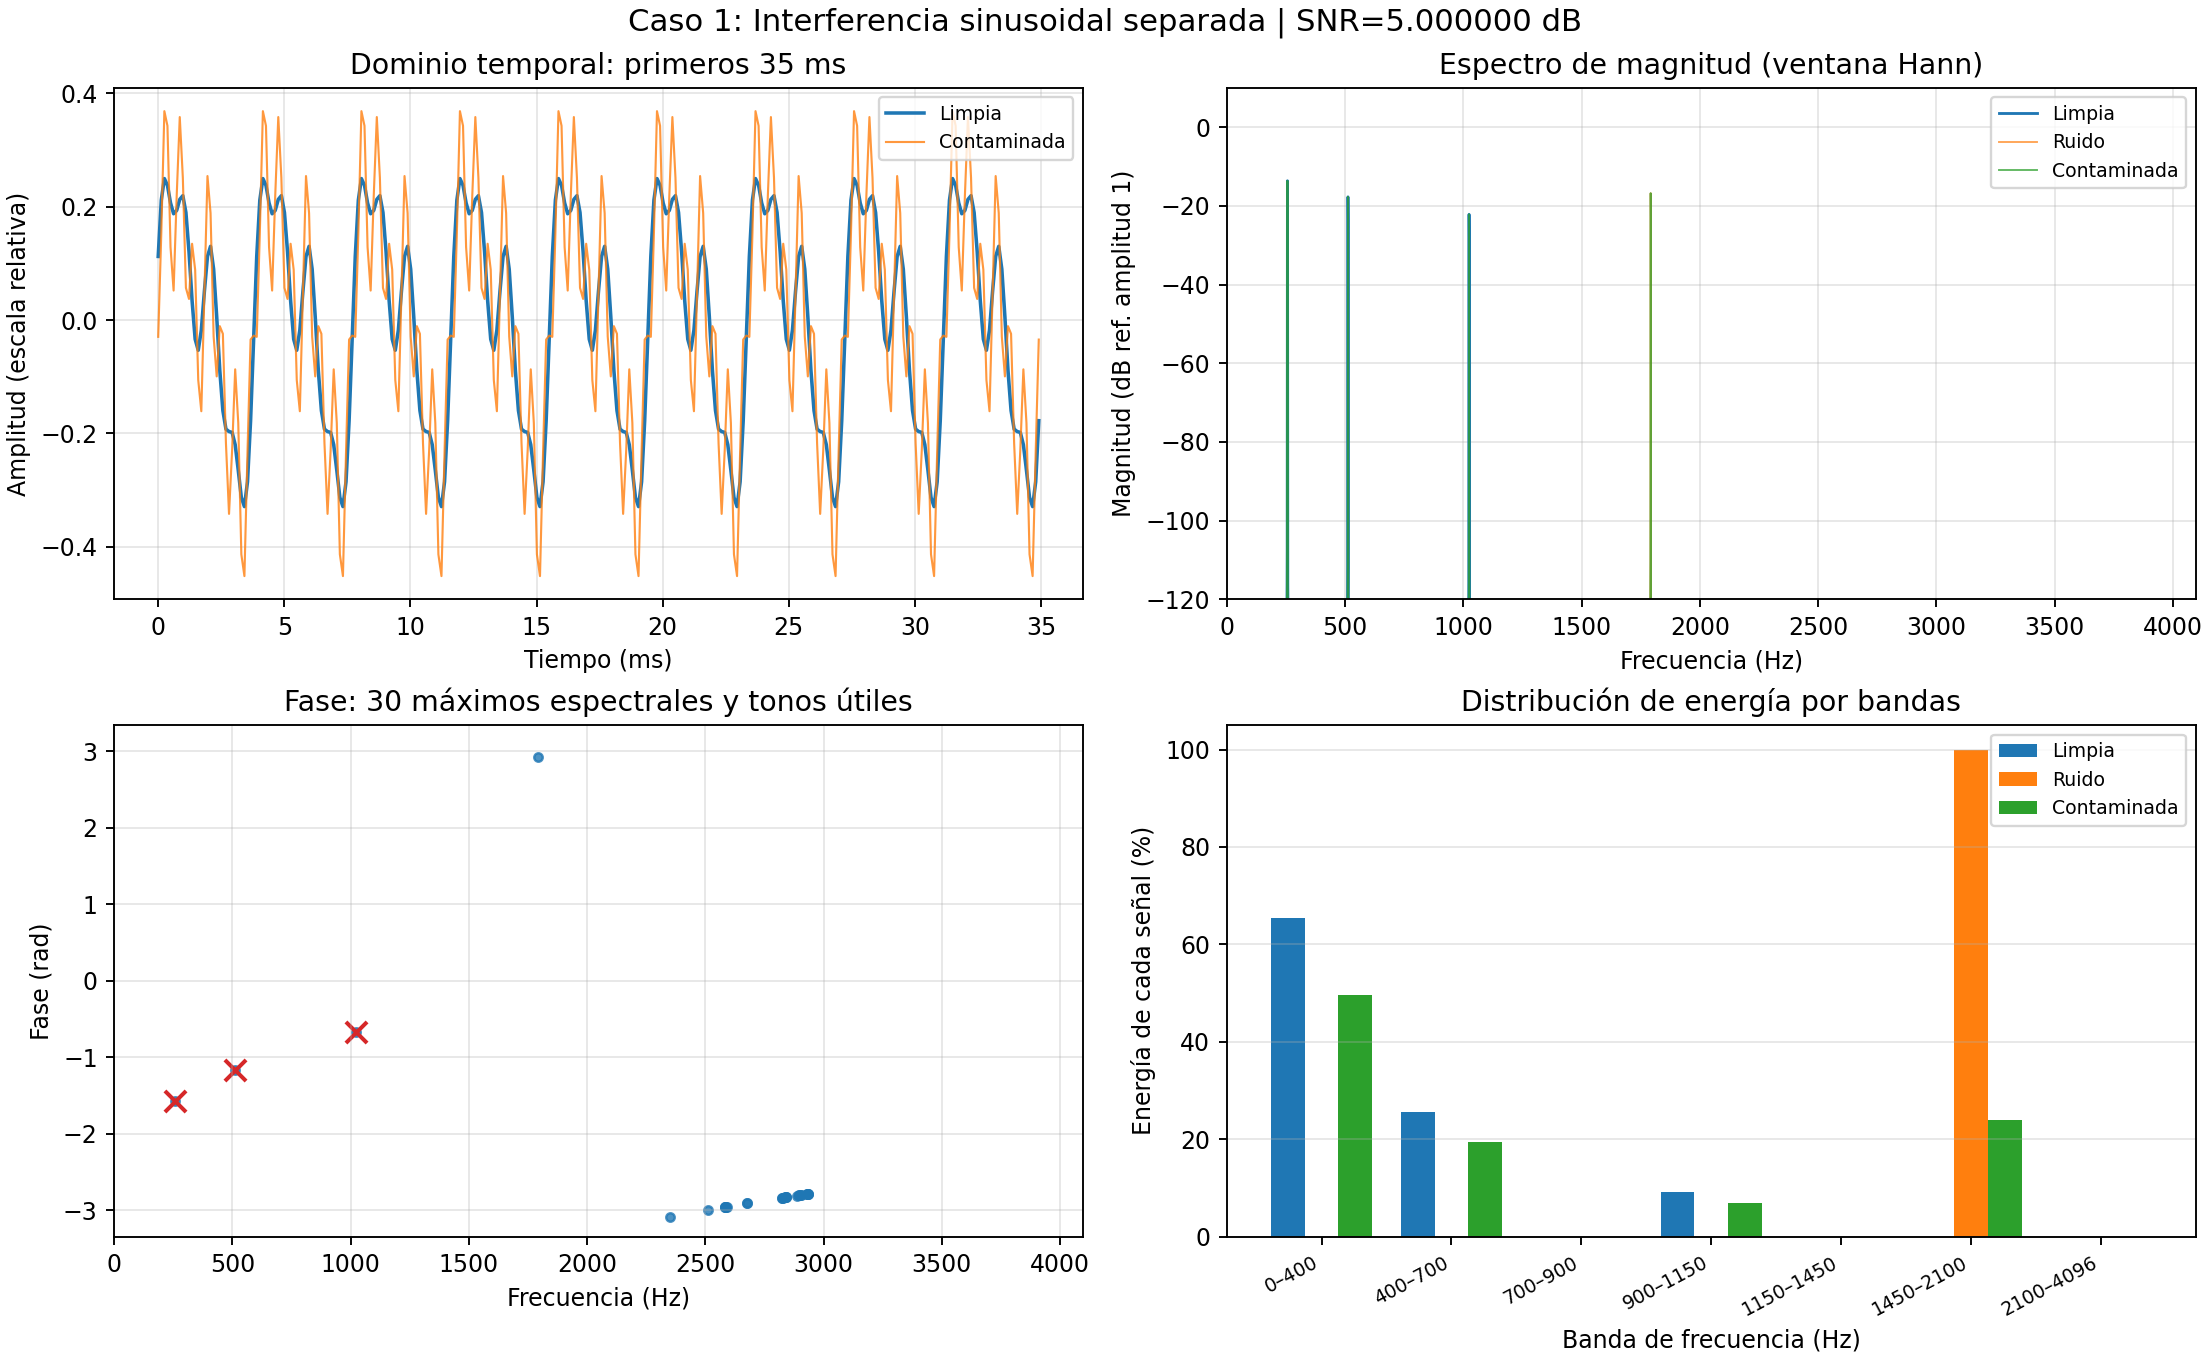

CASO 1: DENSIDAD ESPECTRAL DE POTENCIA


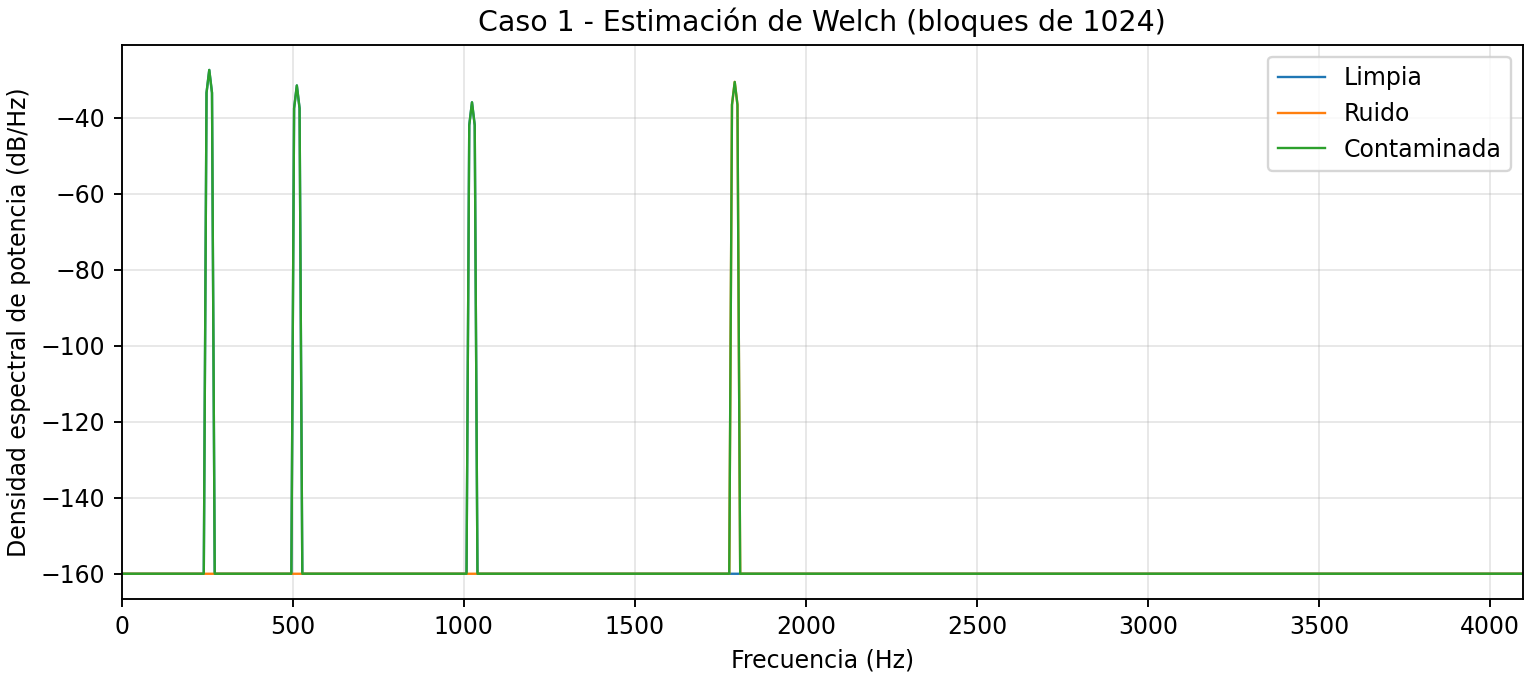

CASO 2: RESUMEN


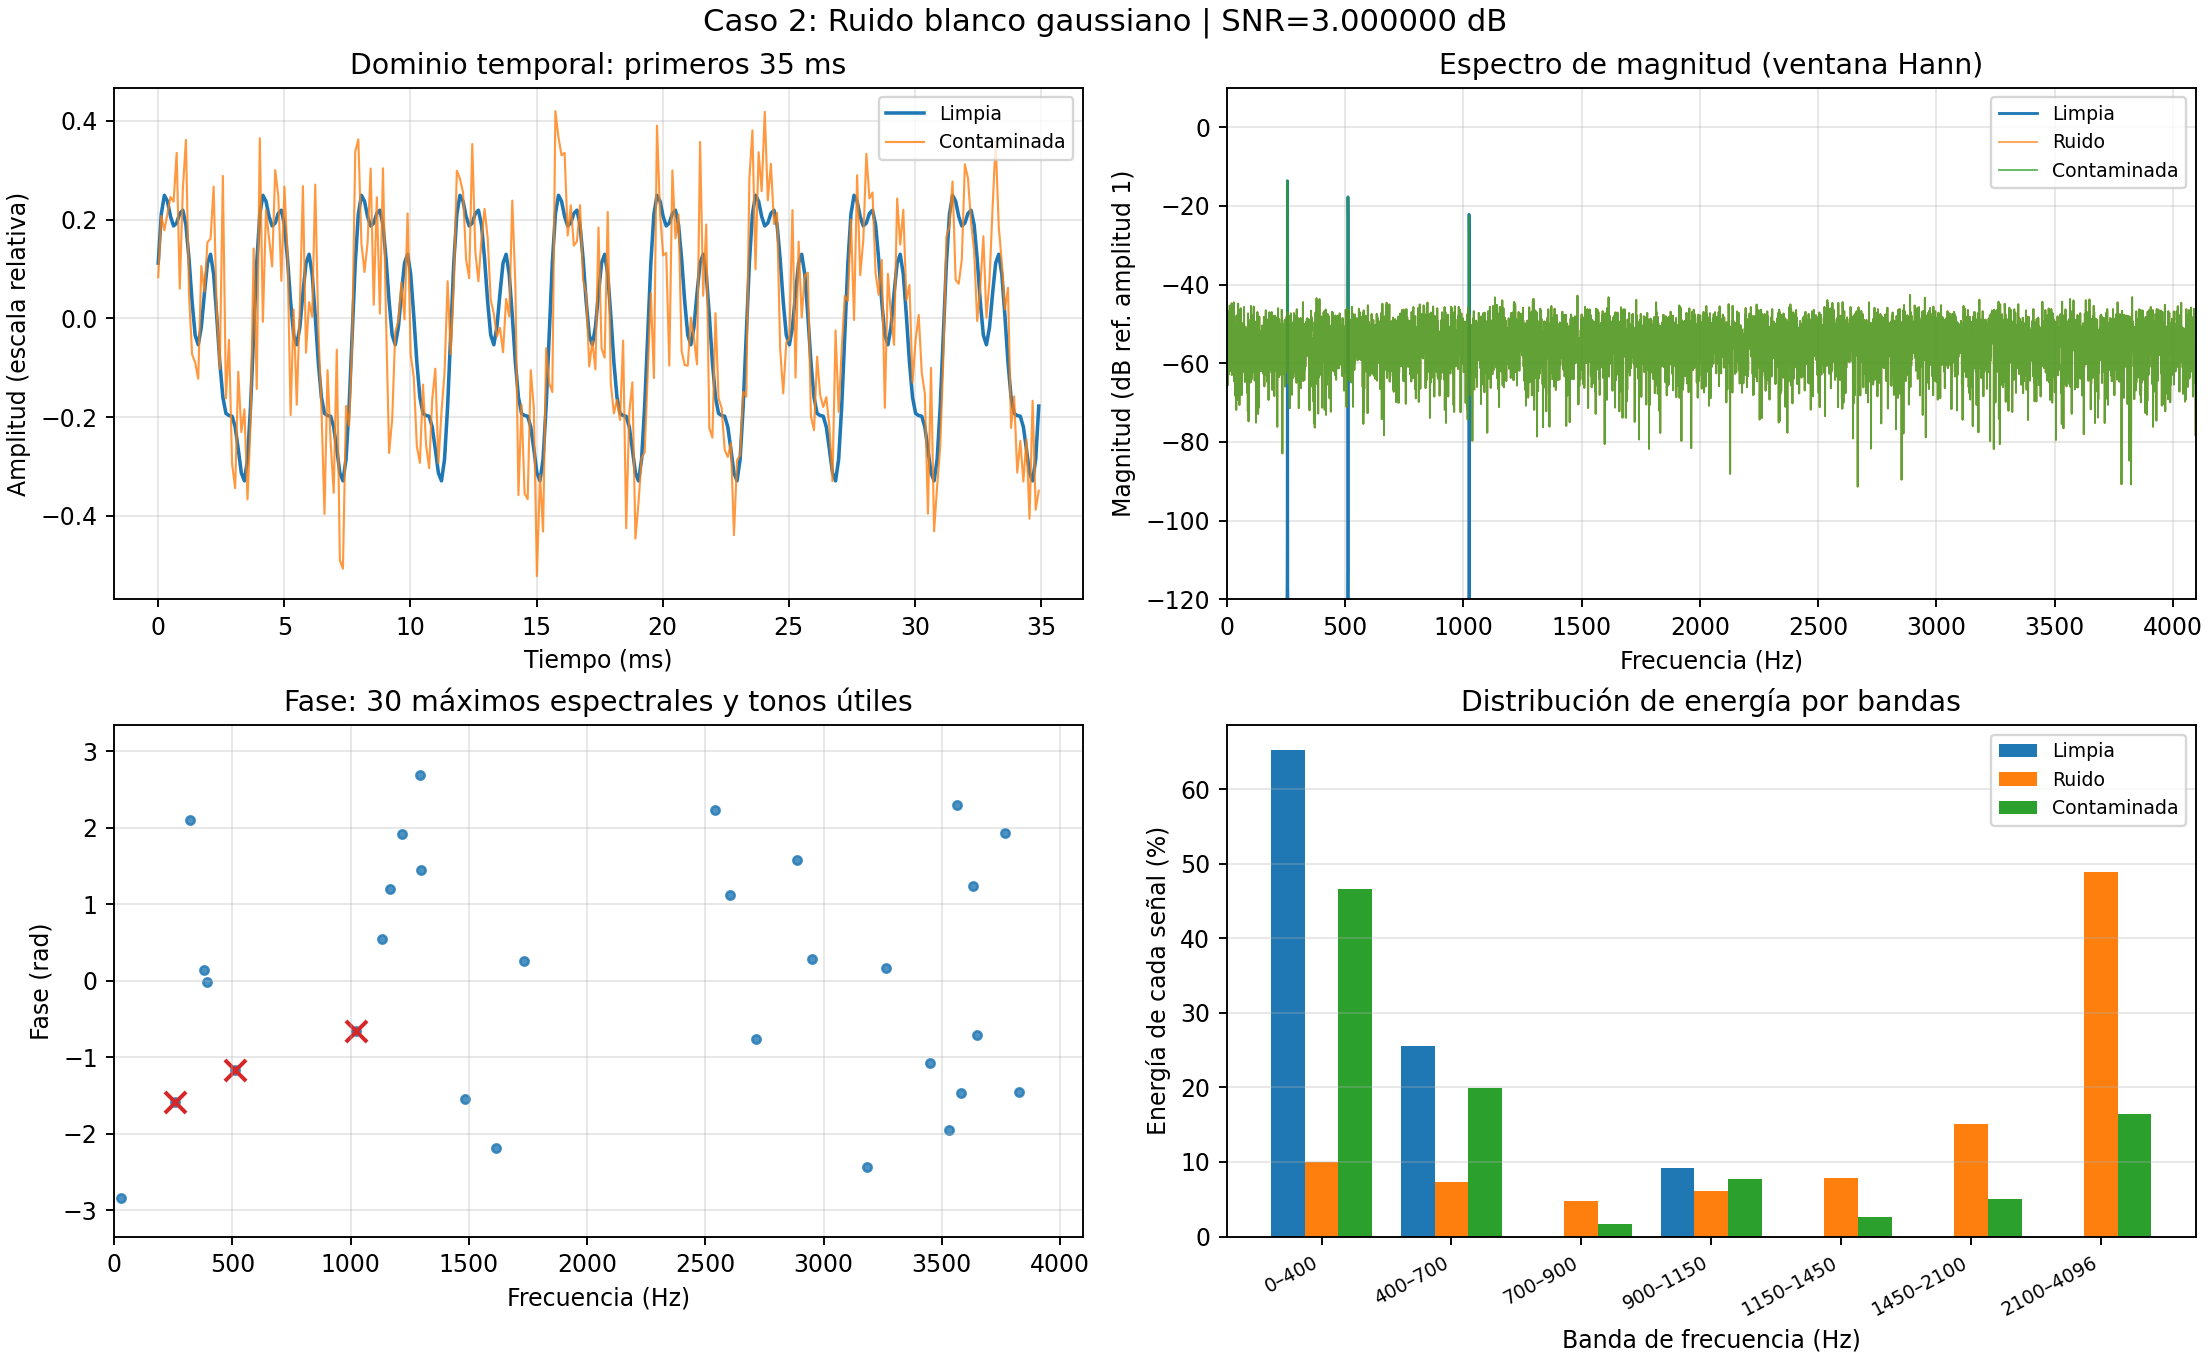

CASO 2: DENSIDAD ESPECTRAL DE POTENCIA


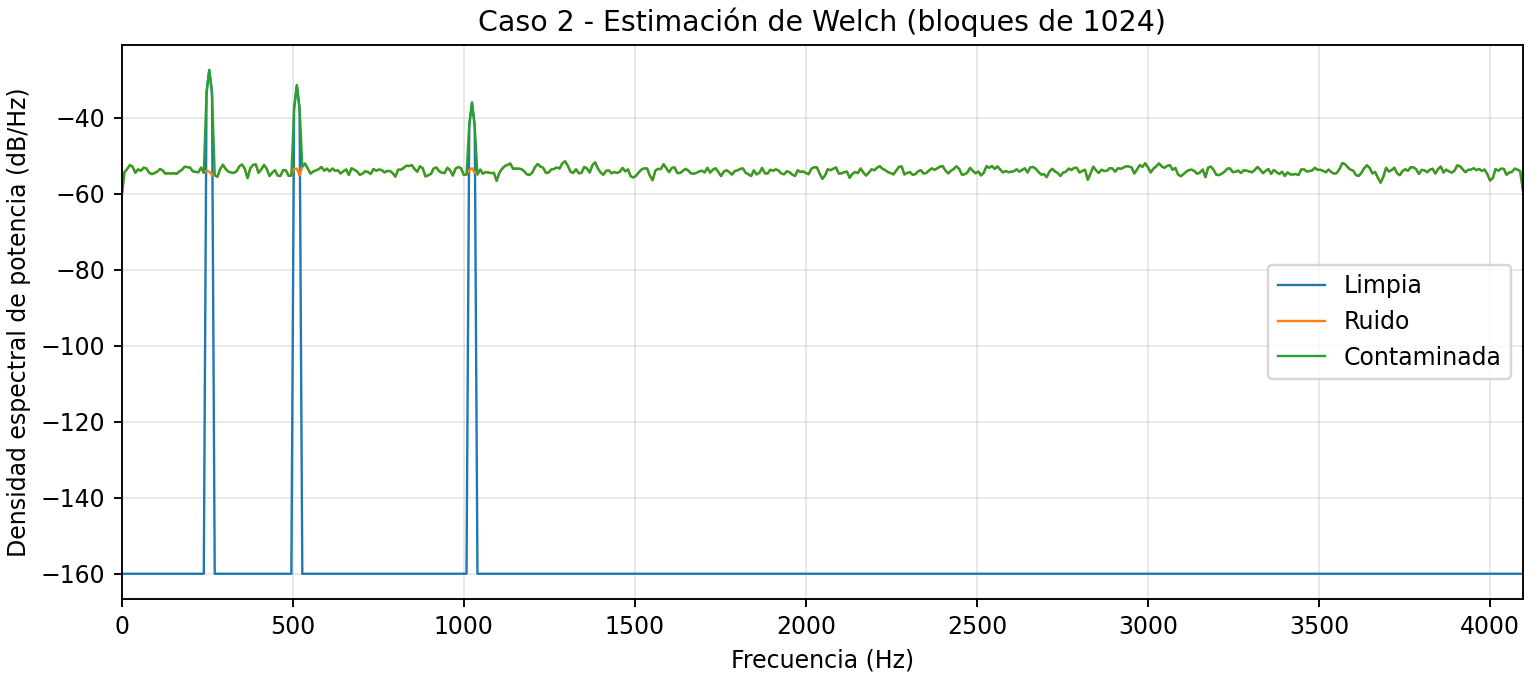

CASO 3: RESUMEN


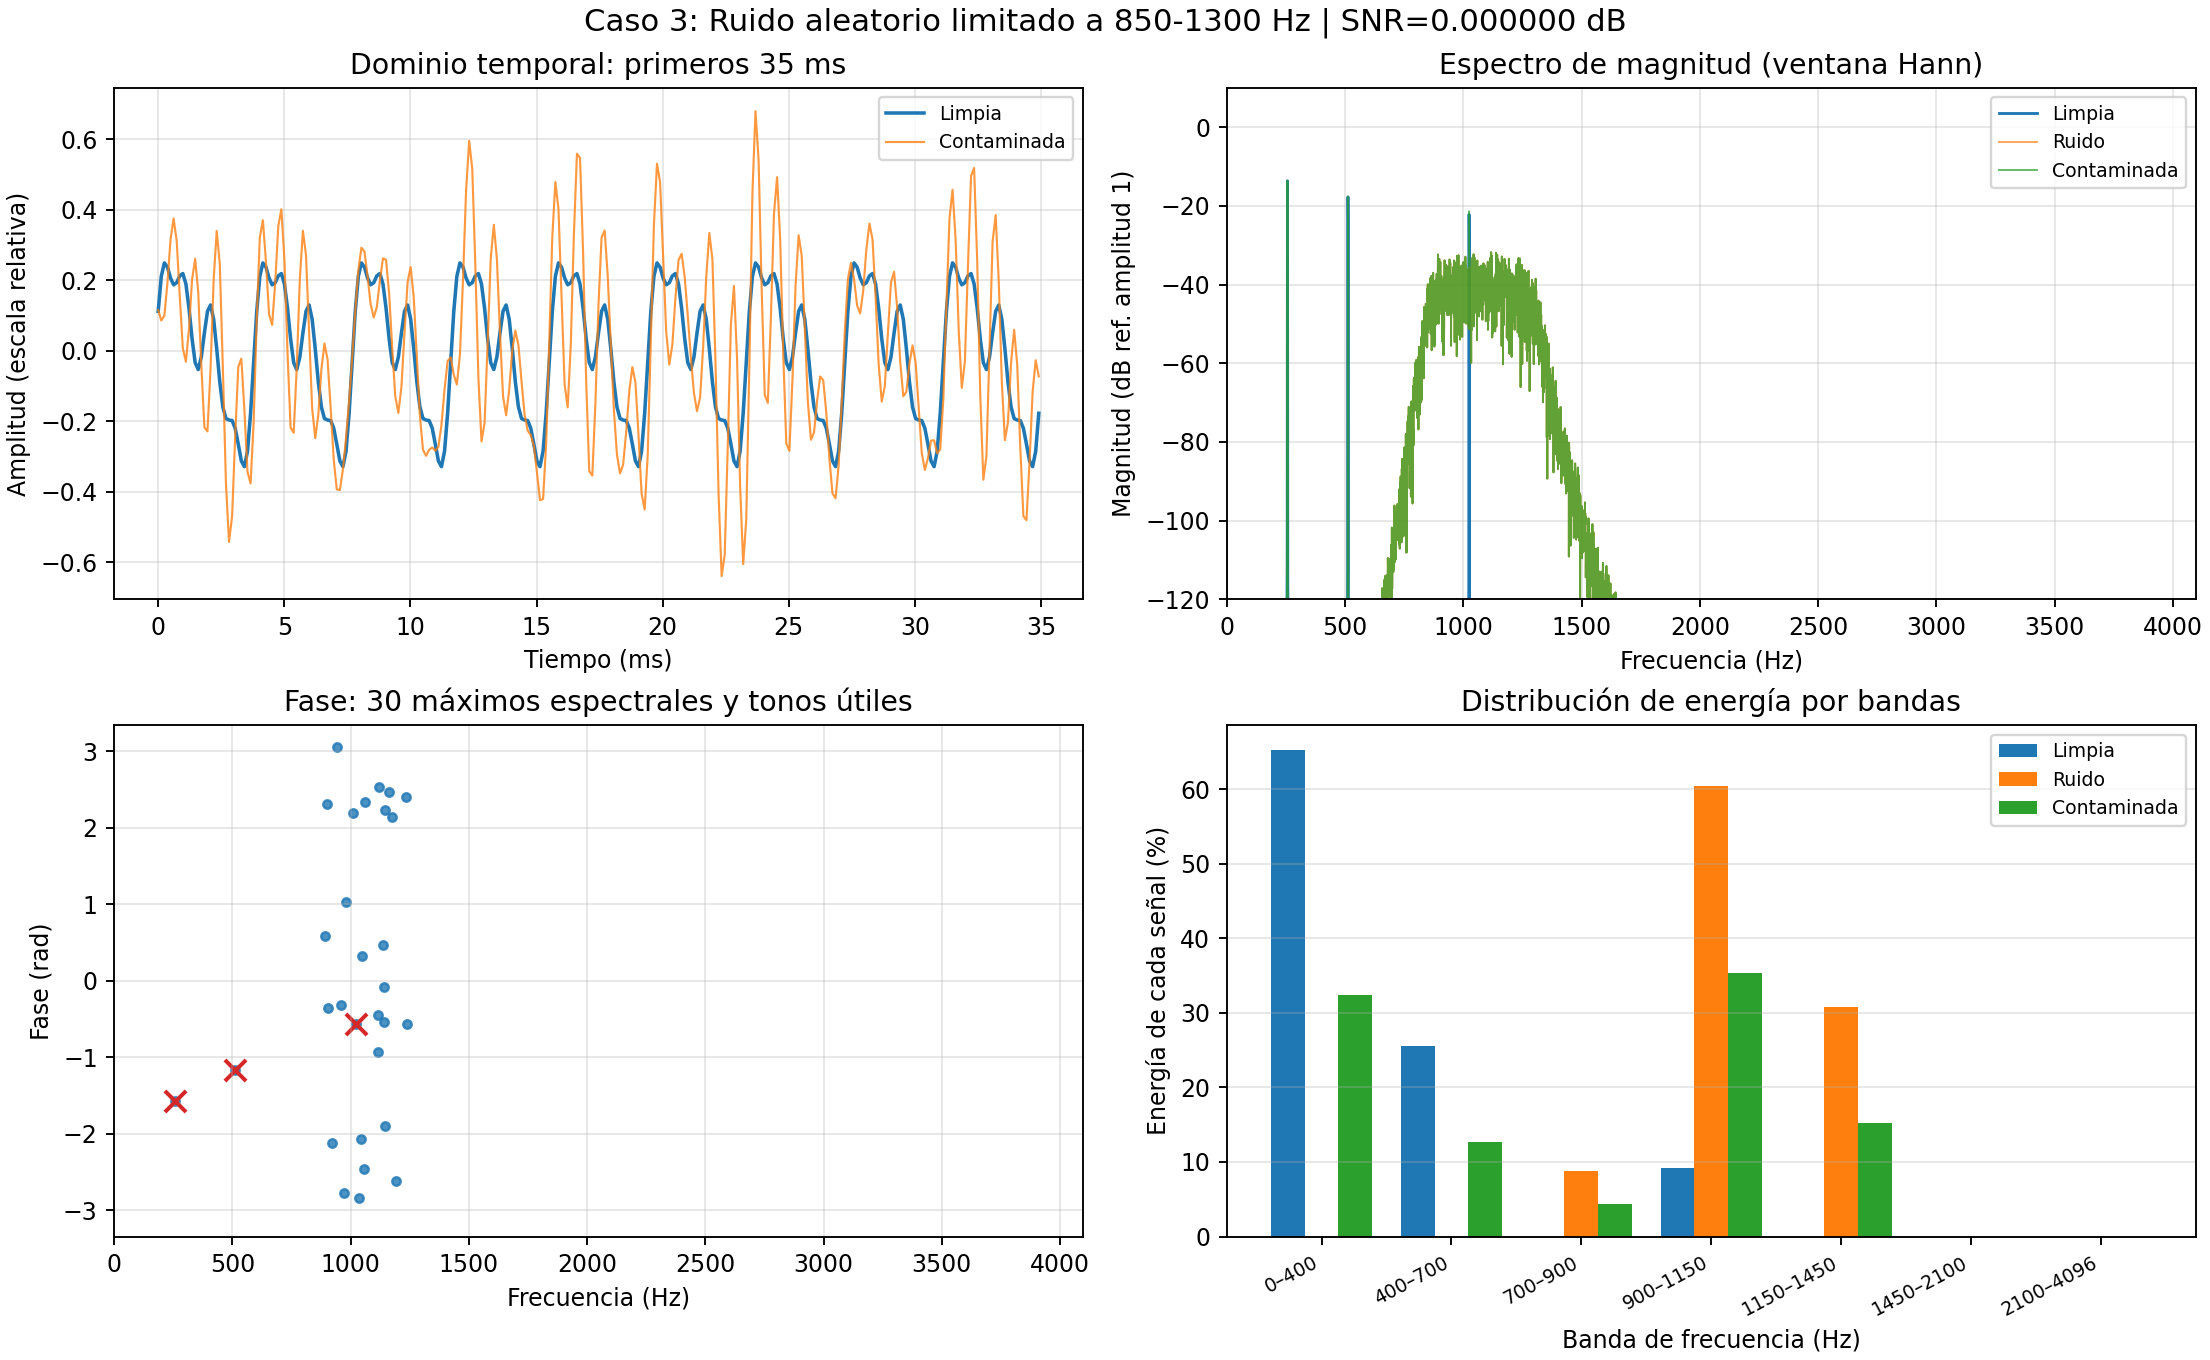

CASO 3: DENSIDAD ESPECTRAL DE POTENCIA


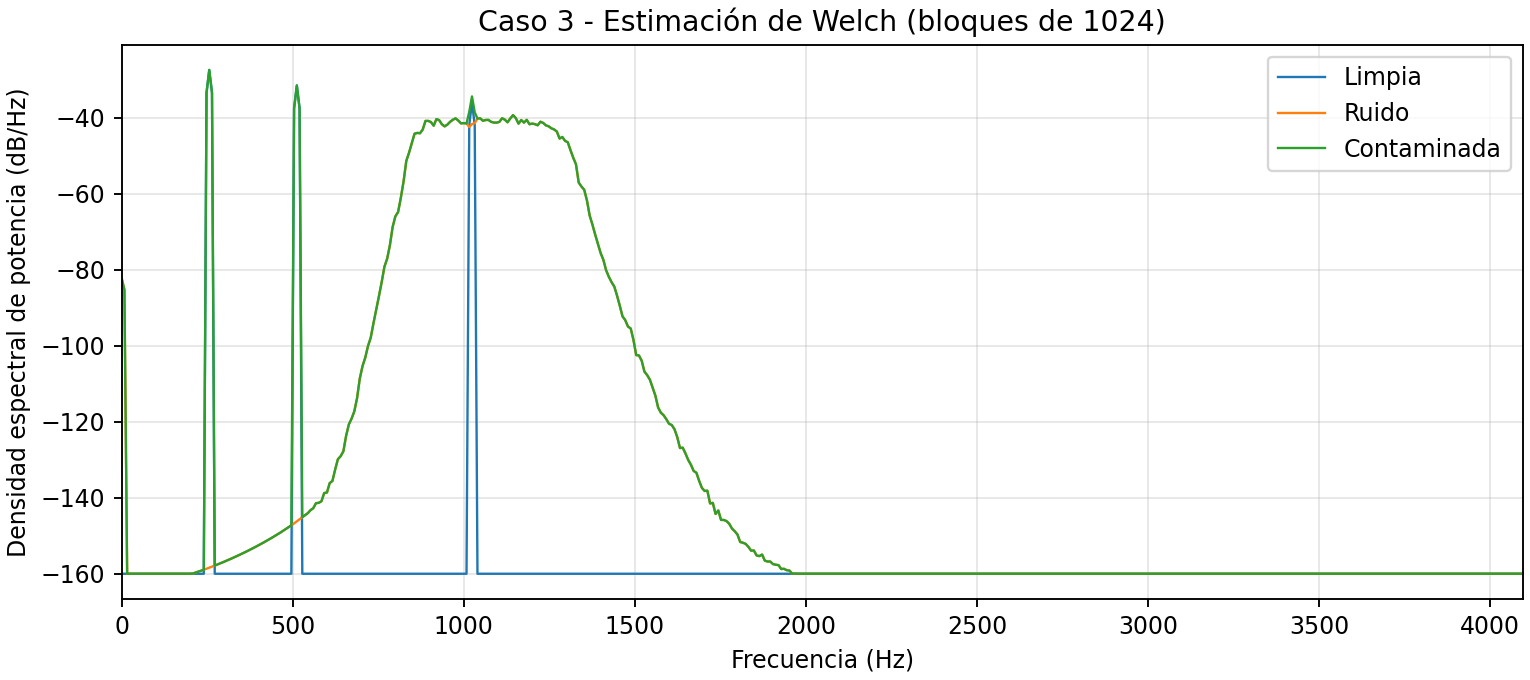

In [4]:
for k in (1,2,3):
    print(f"CASO {k}: RESUMEN")
    display(Image(filename=str(BASE / "resultados" / "figuras" / f"caso{k}_resumen.png"), width=900))
    print(f"CASO {k}: DENSIDAD ESPECTRAL DE POTENCIA")
    display(Image(filename=str(BASE / "resultados" / "figuras" / f"caso{k}_psd.png"), width=740))

## 4. Caracterización y limitaciones

- **Caso 1:** interferencia coherente muy estrecha a 1792 Hz, separada de la banda con los tres tonos útiles. Su pico puede detectarse por contraste respecto a la mediana del espectro, pero no basta para saber si es interferencia sin información previa.
- **Caso 2:** ruido blanco aleatorio con energía distribuida ampliamente; su fase no sigue una relación estable entre bins. Puede estimarse la densidad de ruido de fondo con Welch o percentiles robustos.
- **Caso 3:** energía interferente mayormente entre 850 y 1300 Hz, coincidente con el tono de 1024 Hz. Sin referencia independiente, dos fuentes compartiendo la frecuencia no pueden separarse exactamente a partir de una sola mezcla. El rechazo reduce ruido y también puede eliminar parte de la componente útil.

---
## 5. Integración de ambos filtros (apartado 2.5)

Se usan **exactamente los archivos `limpia.npy`, `ruido.npy` y `contaminada.npy`** creados arriba. El filtrado temporal utiliza la implementación propia SOS Butterworth del compañero; el espectral aplica la regla original de umbral relativo de magnitud con **corrección explícita de cobertura de bordes y OLA**. El archivo `src/filtrado_espectral_original.py` guarda la versión recibida; la integrada está en `src/filtrado_espectral.py`.

Para que las filas de la tabla sean comparables, se emplea **umbral 0.10 en los tres casos**. El umbral agresivo 0.85 se ensaya por separado sobre el caso 3 como demostración del compromiso ruido/distorsión. La señal limpia no interviene en la estimación de ruido del algoritmo; solo en el cálculo *posterior* de métricas de referencia.

In [5]:
from comparar_metodos import generar_metricas

# Crea y guarda resultados/metricas.csv, las salidas de cada filtro,
# una tabla de compromiso adicional y dos figuras comparativas.
# El benchmark se mide en ESTA computadora (NO en el microcontrolador).
filas, compromiso = generar_metricas(BASE, repeticiones=5, crear_figuras=True)

metricas = pd.read_csv(BASE / "resultados" / "metricas.csv")
assert len(metricas) == 9
assert metricas.groupby("caso").size().to_dict() == {1: 3, 2: 3, 3: 3}
assert np.isfinite(metricas[["mse","snr_entrada_db","snr_salida_db","mejora_snr_db"]].to_numpy()).all()
print("Archivo generado:", BASE / "resultados" / "metricas.csv")
print("Filas:", len(metricas))

Archivo generado: /mnt/data/ASM_Tarea1_Integrada/tarea1/resultados/metricas.csv
Filas: 9


### Métricas cuantitativas y lectura técnica

- **MSE / SNR de salida:** se comparan muestras de referencia `s[n]` y salida `y[n]` **sin compensar el retardo**, como exige la comparación directa del enunciado. El filtro IIR cambia la fase de los tonos, por lo que puede dar SNR de salida negativa aun cuando su respuesta en magnitud conserve las componentes útiles.
- **Energía útil conservada:** `100 * E(s_filtrada) / E(s)`; para el método espectral, `s_filtrada` se obtiene **congelando la máscara que se estimó solo de la mezcla contaminada**, sin utilizar la señal limpia para seleccionar coeficientes. Esto es una evaluación offline con referencia conocida, no una estimación posible en condiciones desconocidas. Puede exceder levemente 100 % debido a la recombinación y al procesamiento por bloques.
- **Atenuación de ruido inyectado:** `10 log10(E(r) / E(r_filtrado))` calculada sobre la componente de ruido conocida. En el método espectral se aplican las mismas máscaras estimadas de la mezcla. No se debe confundir con una atenuación medible sin referencias en un entorno real.
- **Tiempo por bloque:** mediana de cinco ejecuciones completas en PC, dividida por el número de bloques procesados. En temporal: 16 bloques, paso 1024; en espectral: 33 ventanas, salto 512. No equivale a latencia medida en ESP32.
- **Memoria aproximada:** presupuesto teórico de arreglos por bloque en `float64`; excluye los datos de 2 s, el intérprete, buffers propios de la FFT y periféricos del hardware.

Las precisiones, limitaciones y condiciones exactas se registran en `resultados/metricas_metodologia.json`. No presentar esas cifras como medidas del microcontrolador.

In [6]:
columnas = ["caso", "metodo", "mse", "snr_entrada_db", "snr_salida_db",
            "mejora_snr_db", "energia_util_conservada_pct",
            "atenuacion_ruido_inyectado_db", "tiempo_por_bloque_ms", "memoria_aprox_bytes"]
display(metricas[columnas].round(5))

,caso,metodo,mse,snr_entrada_db,snr_salida_db,mejora_snr_db,energia_util_conservada_pct,atenuacion_ruido_inyectado_db,tiempo_por_bloque_ms,memoria_aprox_bytes
0,1,Sin filtrar,0.01055,5.0,5.00000,0.00000,100.00000,0.00000,0.00000,0
1,1,Temporal,0.08301,5.0,-3.95902,-8.95902,99.57113,46.43194,13.86709,16864
2,1,Espectral,0.01054,5.0,5.00319,0.00319,99.82677,0.00962,0.02944,81920
3,2,Sin filtrar,0.01672,3.0,3.00000,0.00000,100.00000,0.00000,0.00000,0
4,2,Temporal,0.08773,3.0,-4.19926,-7.19926,99.57113,5.47075,13.66245,16864
5,2,Espectral,0.00145,3.0,13.60877,10.60877,99.89912,10.66478,0.02852,81920
6,3,Sin filtrar,0.03336,0.0,0.00000,0.00000,100.00000,0.00000,0.00000,0
7,3,Temporal,0.10660,0.0,-5.04544,-5.04544,99.57113,1.54822,13.74066,16864
8,3,Espectral,0.03211,0.0,0.16651,0.16651,100.00589,0.17747,0.03226,81920


### Comparación visual de los tres casos

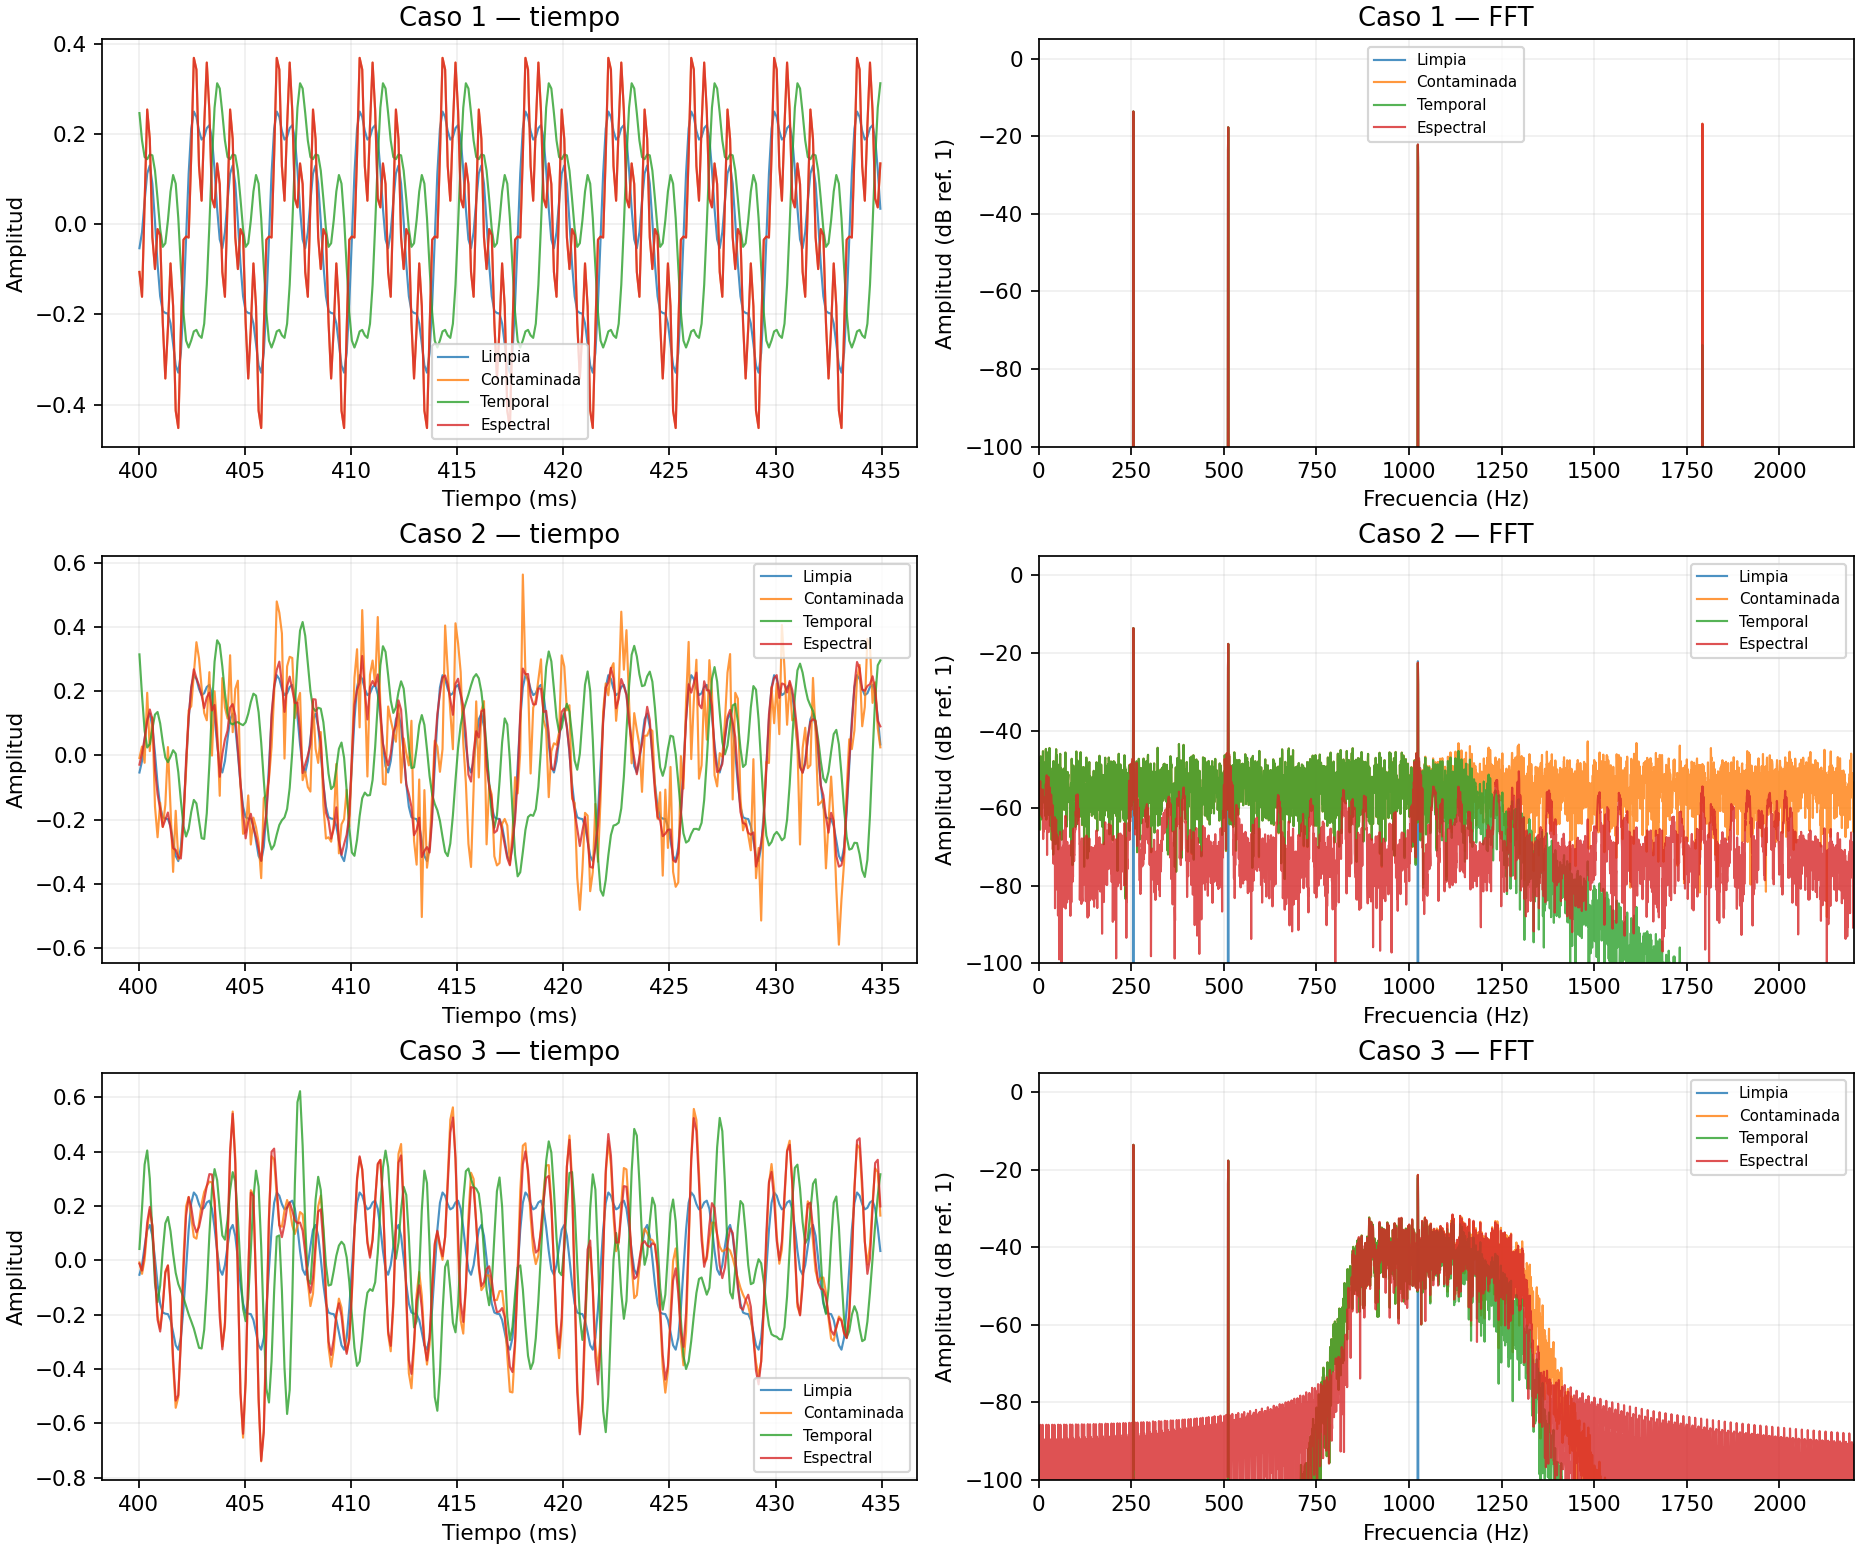

In [7]:
display(Image(filename=str(BASE / "resultados" / "figuras" / "comparacion_metodos.png"), width=1000))

### Compromiso entre eliminación de ruido y distorsión (caso 3)

Al incrementar el umbral relativo de 0.10 a 0.85 se atenúan **más componentes**, pero las que correspondían a la señal útil también pueden verse afectadas. Para comparar rigurosamente deben examinarse **dos** magnitudes a la vez: SNR/MSE total de la mezcla tratada y la energía de la referencia útil que habría sobrevivido con la misma máscara. Un aumento de la SNR no implica que todo el contenido útil se haya conservado.

,caso,ajuste,mse,snr_salida_db,energia_util_conservada_pct,mse_senal_limpia_filtrada
0,3,conservador_0.10,0.03211,0.16651,100.00589,0.00006
1,3,agresivo_0.85,0.00973,5.35087,64.02314,0.00944


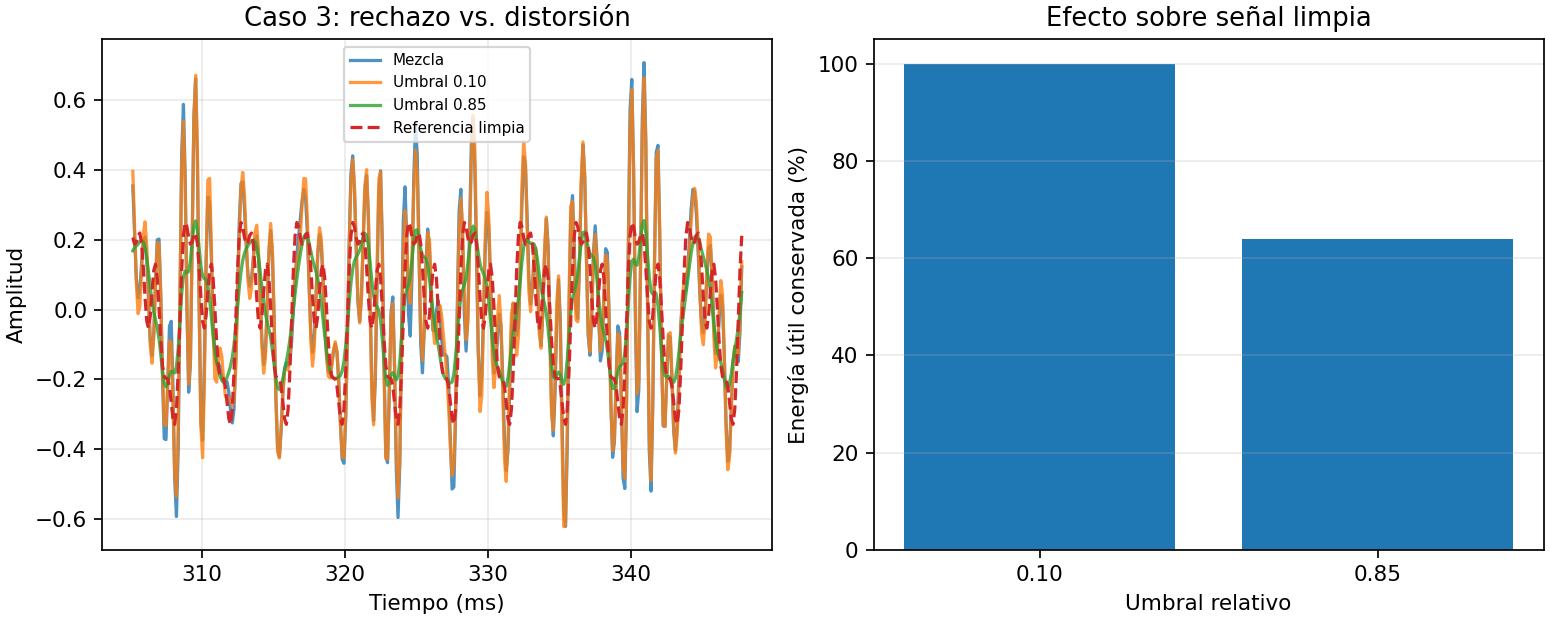

In [8]:
display(pd.read_csv(BASE / "resultados" / "espectral_compromiso.csv").round(5))
display(Image(filename=str(BASE / "resultados" / "figuras" / "espectral_compromiso.png"), width=900))

## 6. Verificaciones y archivos para el equipo

El archivo `resultados/metricas.csv` contiene **nueve filas** para completar la tabla del apartado 2.5. Las señales filtradas se guardan en `resultados/temporal/caso_i/filtrada.npy` y `resultados/espectral/caso_i/filtrada.npy`. Se conserva `resultados/metricas_generacion.csv` para la validación de entrada del apartado 2.2.

También pueden ejecutarse las pruebas desde una terminal abierta en `tarea1`:

```bash
python -m unittest discover -s pruebas -p "test_*.py" -v
python src/comparar_metodos.py
```

**Revisión pendiente con la persona 4:** confirmar y aceptar la corrección de bordes y de normalización OLA antes de integrar estos resultados a la rama oficial. El código original se preservó para comparación.